
# Abuja Rain Prediction

## 01 — Data Exploration

### Project Objective
Develop a machine learning model that predicts whether rainfall will occur on a given day in Abuja, Nigeria.

### Data Source
Open-Meteo Historical Weather API.

### Historical Period
January 2015 – December 2025.

### Dataset
`abuja_weather.csv`

### Target Variable
`rain`
- 1 = Rain
- 0 = No rain

A day is classified as rainy when precipitation exceeds 0.1 mm.


In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("../data/abuja_weather.csv")

df.head()

,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,rain
0,2015-01-01,33.7,22.5,27.8,0.0,0.0,10.2,29.2,21.56,0
1,2015-01-02,33.8,20.9,27.0,0.0,0.0,11.3,22.7,22.11,0
2,2015-01-03,33.9,20.3,26.6,0.0,0.0,15.0,33.8,22.24,0
3,2015-01-04,32.7,19.0,25.4,0.0,0.0,15.4,32.4,22.29,0
4,2015-01-05,31.7,18.3,24.7,0.0,0.0,14.0,29.9,22.23,0


In [4]:
df.tail()

,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,rain
4013,2025-12-27,35.7,23.0,29.4,0.0,0.0,9.8,23.8,20.07,0
4014,2025-12-28,36.7,22.7,29.3,0.0,0.0,14.2,29.2,20.23,0
4015,2025-12-29,36.1,23.9,29.6,0.0,0.0,10.7,25.2,19.32,0
4016,2025-12-30,36.3,23.1,29.4,0.0,0.0,14.2,29.9,19.29,0
4017,2025-12-31,37.0,24.2,30.5,0.0,0.0,12.5,25.9,18.99,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4018 entries, 0 to 4017
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   time                     4018 non-null   object 
 1   temperature_2m_max       4018 non-null   float64
 2   temperature_2m_min       4018 non-null   float64
 3   temperature_2m_mean      4018 non-null   float64
 4   precipitation_sum        4018 non-null   float64
 5   precipitation_hours      4018 non-null   float64
 6   wind_speed_10m_max       4018 non-null   float64
 7   wind_gusts_10m_max       4018 non-null   float64
 8   shortwave_radiation_sum  4018 non-null   float64
 9   rain                     4018 non-null   int64  
dtypes: float64(8), int64(1), object(1)
memory usage: 314.0+ KB


In [6]:
df["time"] = pd.to_datetime(df["time"])

print("Date conversion successful!")
print(df["time"].dtype)

Date conversion successful!
datetime64[ns]


In [7]:
df.describe()

,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,rain
count,4018,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000
mean,2020-07-01 12:00:00,31.553285,22.276854,26.452389,2.640941,3.963415,11.551867,27.347785,18.831518,0.480090
min,2015-01-01 00:00:00,22.000000,17.000000,20.900000,0.000000,0.000000,4.700000,14.400000,3.070000,0.000000
25%,2017-10-01 06:00:00,28.600000,21.125000,24.500000,0.000000,0.000000,9.000000,23.800000,16.422500,0.000000
50%,2020-07-01 12:00:00,32.100000,22.000000,26.600000,0.100000,1.000000,10.800000,26.600000,20.200000,0.000000
75%,2023-04-01 18:00:00,34.400000,23.300000,28.200000,3.000000,7.000000,13.400000,30.200000,21.750000,1.000000
max,2025-12-31 00:00:00,39.300000,28.300000,32.900000,68.800000,24.000000,26.300000,53.600000,28.210000,1.000000
std,NaN,3.485477,1.540235,2.329538,5.294364,5.598500,3.563349,5.316829,4.085088,0.499666


In [8]:
df["rain"].value_counts()

rain
0    2089
1    1929
Name: count, dtype: int64

In [9]:
df["rain"].value_counts(normalize=True) * 100

rain
0    51.99104
1    48.00896
Name: proportion, dtype: float64

In [10]:
df["month"] = df["time"].dt.month

monthly_rainfall = df.groupby("month")["rain"].mean() * 100

monthly_rainfall.round(2)

month
1      0.59
2      8.04
3     19.06
4     33.33
5     64.52
6     83.94
7     96.19
8     96.77
9     95.76
10    68.33
11     6.67
12     0.29
Name: rain, dtype: float64

In [11]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


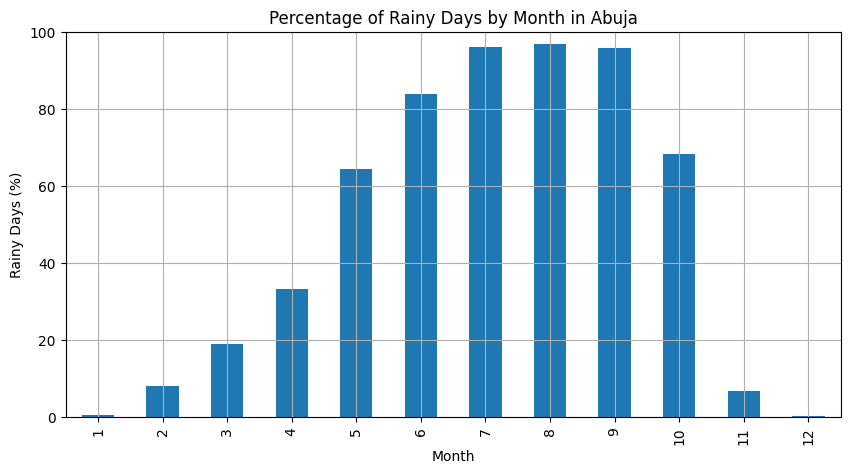

In [12]:
monthly_rainfall.plot(
    kind="bar",
    figsize=(10, 5),
    title="Percentage of Rainy Days by Month in Abuja",
    xlabel="Month",
    ylabel="Rainy Days (%)",
    ylim=(0, 100),
    grid=True
);

In [13]:
df["precipitation_sum"].describe()

count    4018.000000
mean        2.640941
std         5.294364
min         0.000000
25%         0.000000
50%         0.100000
75%         3.000000
max        68.800000
Name: precipitation_sum, dtype: float64

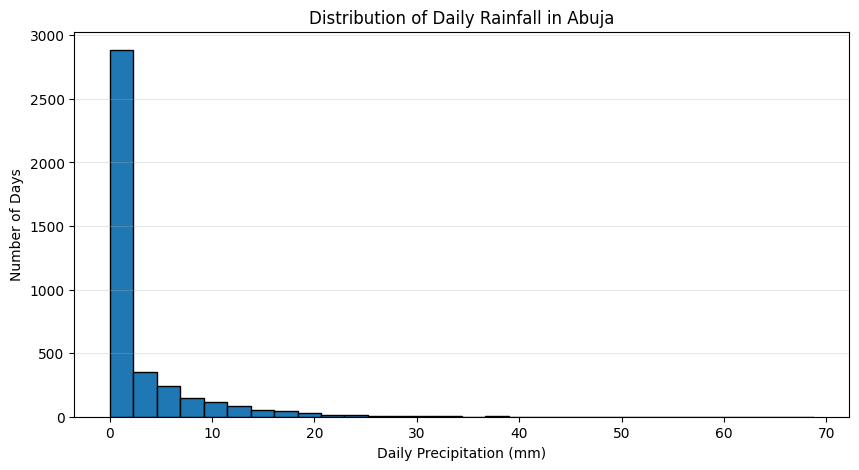

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["precipitation_sum"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Daily Rainfall in Abuja")
plt.xlabel("Daily Precipitation (mm)")
plt.ylabel("Number of Days")

plt.grid(axis="y", alpha=0.3)
plt.show()

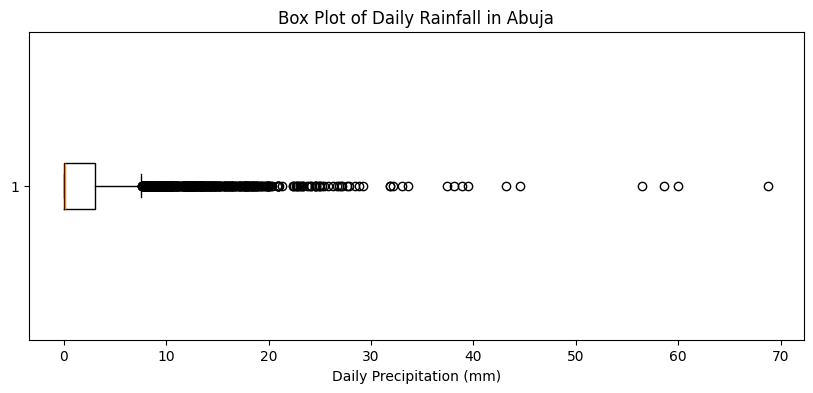

In [15]:
plt.figure(figsize=(10, 4))

plt.boxplot(df["precipitation_sum"], vert=False)

plt.title("Box Plot of Daily Rainfall in Abuja")
plt.xlabel("Daily Precipitation (mm)")

plt.show()

### Box Plot Interpretation

The box plot reveals a highly right-skewed rainfall distribution.

- The median daily precipitation is 0.1 mm.
- The first quartile is 0 mm.
- The third quartile is 3 mm.
- Several high-rainfall observations appear as statistical outliers.
- The maximum daily precipitation is 68.8 mm.

These extreme observations may represent genuine heavy rainfall events and should not automatically be removed.

In [16]:
weather_features = [
    "temperature_2m_max",
    "temperature_2m_min",
    "temperature_2m_mean",
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "shortwave_radiation_sum"
]

rain_comparison = df.groupby("rain")[weather_features].mean().T

rain_comparison.columns = ["No Rain", "Rain"]

rain_comparison.round(2)

,No Rain,Rain
temperature_2m_max,34.05,28.85
temperature_2m_min,22.60,21.92
temperature_2m_mean,27.96,24.82
wind_speed_10m_max,12.79,10.21
wind_gusts_10m_max,28.19,26.44
shortwave_radiation_sum,21.28,16.17


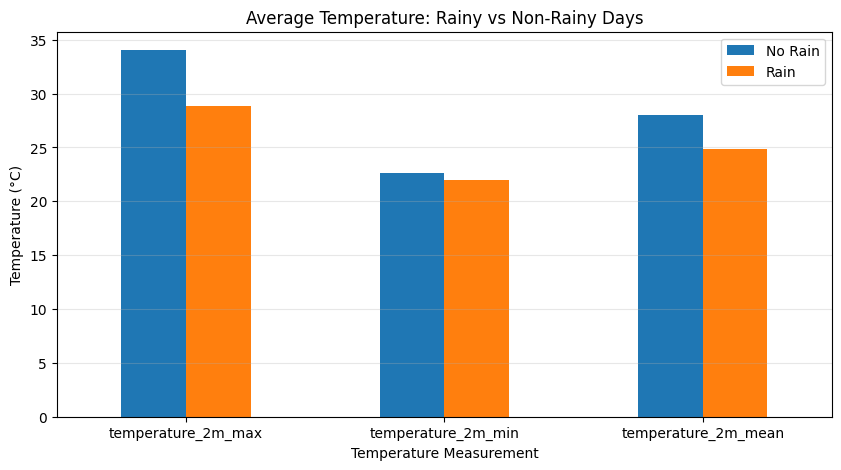

In [17]:
temperature_comparison = rain_comparison.loc[
    [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean"
    ]
]

temperature_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Temperature: Rainy vs Non-Rainy Days",
    ylabel="Temperature (°C)",
    xlabel="Temperature Measurement"
)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


### Temperature Comparison: Rainy vs Non-Rainy Days

The temperature comparison shows noticeable differences between rainy and non-rainy days in Abuja.

- Average maximum temperature was 28.85°C on rainy days compared to 34.05°C on non-rainy days.
- Average minimum temperature was 21.92°C on rainy days compared to 22.60°C on non-rainy days.
- Average mean temperature was 24.82°C on rainy days compared to 27.96°C on non-rainy days.

The results indicate that rainy days generally experience lower temperatures, particularly in maximum and mean temperature measurements.

These observations suggest that temperature measurements may provide useful information for rainfall classification. However, they represent associations rather than causal relationships.


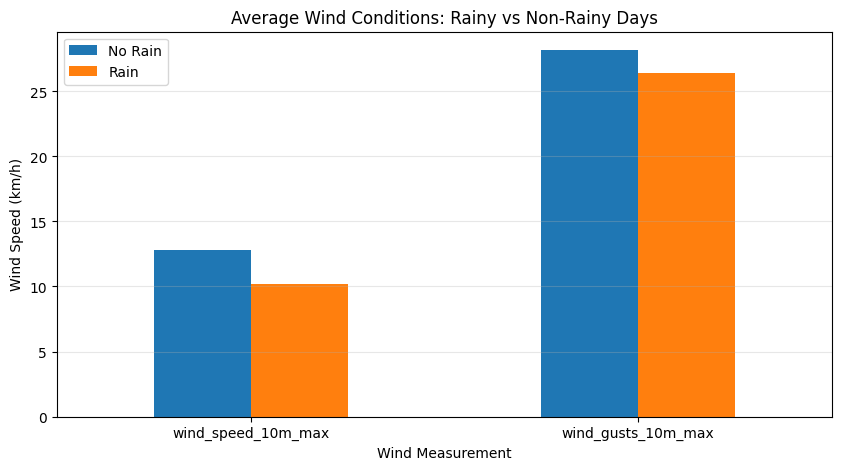

In [18]:
wind_comparison = rain_comparison.loc[
    [
        "wind_speed_10m_max",
        "wind_gusts_10m_max"
    ]
]

wind_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Wind Conditions: Rainy vs Non-Rainy Days",
    ylabel="Wind Speed (km/h)",
    xlabel="Wind Measurement"
)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


### Wind Conditions: Rainy vs Non-Rainy Days

The wind comparison reveals differences in average wind conditions between rainy and non-rainy days in Abuja.

- Average maximum wind speed was 12.79 km/h on non-rainy days and 10.21 km/h on rainy days.
- Average maximum wind gust speed was 28.19 km/h on non-rainy days and 26.44 km/h on rainy days.

Both measurements recorded slightly higher averages on non-rainy days.

The differences suggest that wind conditions may have some relationship with rainfall patterns. However, further statistical and machine learning analysis will be required to determine their predictive usefulness.


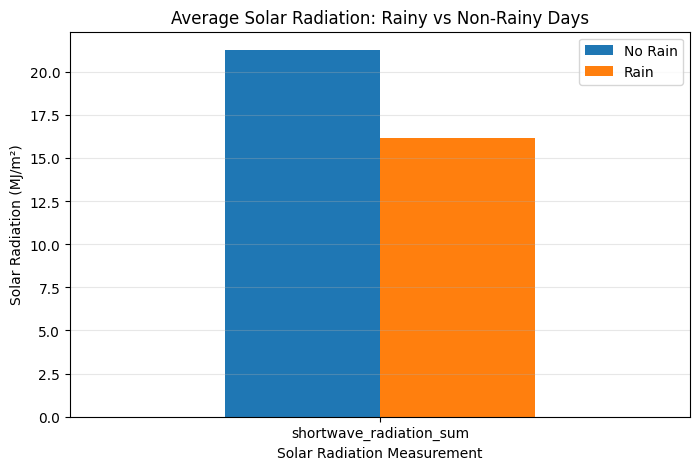

In [19]:
solar_comparison = rain_comparison.loc[
    [
        "shortwave_radiation_sum"
    ]
]

solar_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Solar Radiation: Rainy vs Non-Rainy Days",
    ylabel="Solar Radiation (MJ/m²)",
    xlabel="Solar Radiation Measurement"
)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


### Solar Radiation: Rainy vs Non-Rainy Days

The solar radiation comparison reveals a noticeable difference between rainy and non-rainy days in Abuja.

- Average solar radiation on non-rainy days was 21.28 MJ/m².
- Average solar radiation on rainy days was 16.17 MJ/m².

Non-rainy days recorded higher average solar radiation than rainy days.

One possible explanation is that increased cloud cover during rainy conditions reduces incoming shortwave solar radiation.

These findings suggest that solar radiation may be useful for understanding historical rainfall patterns. Further analysis will be required to establish its predictive usefulness.


In [20]:
correlation_data = df.drop(
    columns=[
        "time",
        "precipitation_sum",
        "precipitation_hours",
        "month"
    ],
    errors="ignore"
)

correlation_matrix = correlation_data.corr()

correlation_matrix.round(2)

,temperature_2m_max,temperature_2m_min,temperature_2m_mean,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,rain
temperature_2m_max,1.00,0.55,0.95,0.37,0.26,0.81,-0.74
temperature_2m_min,0.55,1.00,0.74,0.06,0.12,0.30,-0.22
temperature_2m_mean,0.95,0.74,1.00,0.29,0.22,0.73,-0.67
wind_speed_10m_max,0.37,0.06,0.29,1.00,0.77,0.24,-0.36
wind_gusts_10m_max,0.26,0.12,0.22,0.77,1.00,0.18,-0.16
shortwave_radiation_sum,0.81,0.30,0.73,0.24,0.18,1.00,-0.63
rain,-0.74,-0.22,-0.67,-0.36,-0.16,-0.63,1.00


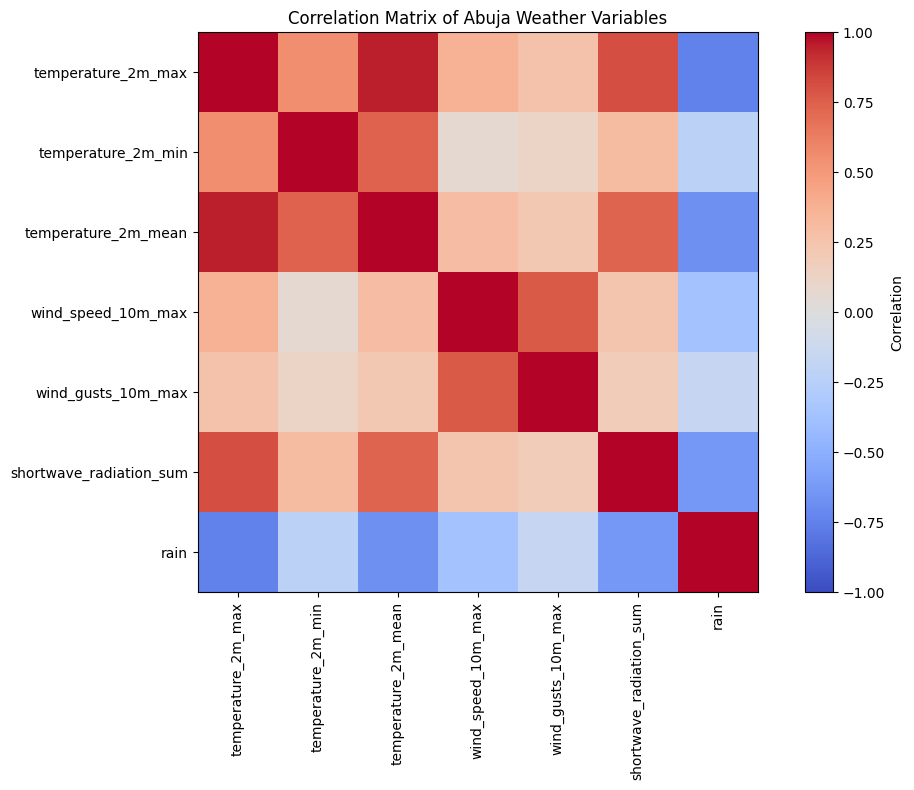

In [21]:
plt.figure(figsize=(11, 8))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix of Abuja Weather Variables")

plt.tight_layout()
plt.show()


### Correlation Analysis of Abuja Weather Variables

The correlation analysis was conducted to examine the relationships between numerical weather variables and rainfall.

The results revealed the following important observations:

**Relationships with rainfall:**

- Maximum temperature had the strongest negative correlation with rainfall (-0.74).
- Mean temperature also showed a strong negative correlation (-0.67).
- Solar radiation had a strong negative correlation (-0.63).
- Maximum wind speed showed a moderate negative correlation (-0.36).
- Minimum temperature (-0.22) and maximum wind gusts (-0.16) showed relatively weak negative correlations.

These findings suggest that temperature and solar radiation measurements have stronger linear associations with the historical rainfall classification than the wind measurements.

**Relationships between weather variables:**

Some predictor variables also showed strong correlations with one another.

- Maximum temperature and mean temperature: 0.95.
- Maximum temperature and solar radiation: 0.81.
- Maximum wind speed and maximum wind gusts: 0.77.
- Mean temperature and solar radiation: 0.73.

These relationships indicate potential multicollinearity among some weather variables, which may affect the interpretation of certain machine learning models.

**Important limitation:**

The correlations were calculated using same-day historical weather observations. They describe relationships within the historical dataset and do not establish that these measurements are available for advance rainfall prediction.

Further investigation will be required to determine which variables are appropriate for the final forecasting model.
